In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
raw_data = pd.read_csv("data/dataset.csv", sep=";", decimal=",", encoding="latin-1")
data = raw_data.copy()
data.head(5)

,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%)
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4.1
1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6.6
2,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8.7
3,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.2
4,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11.1


In [30]:
# Tratemento dos dados
incidentes = [col for col in data.columns if col not in ["Slowness in traffic (%)", "Hour (Coded)"]]
data["day_coded"] = np.arange(len(data)) / 28
data['day_coded'] = data['day_coded'].astype(int)
data['Hour (Coded)'] = data['Hour (Coded)'].astype(int)
data['has_incident'] = (data[incidentes].sum(axis=1) > 0).astype(int)
data['incident_total'] = data[incidentes].sum(axis=1)
data.head()

,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%),day_coded,has_incident,incident_total
0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4.1,0,0,0
1,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,6.6,0,0,0
2,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8.7,0,0,0
3,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9.2,0,0,0
4,5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,11.1,0,0,0


In [31]:
# Analíse Exploratória
print(f"Ausentes:\n{data.isna().sum()}")
print(f"\nDimensões: {data.shape}\n")
slowness_describe = data['Slowness in traffic (%)'].describe()
slowness_describe["variance"] = data['Slowness in traffic (%)'].var()
slowness_describe["iqr"] = data['Slowness in traffic (%)'].quantile(0.75) - data['Slowness in traffic (%)'].quantile(0.25)
slowness_describe


Ausentes:
Hour (Coded)                             0
Immobilized bus                          0
Broken Truck                             0
Vehicle excess                           0
Accident victim                          0
Running over                             0
Fire vehicles                            0
Occurrence involving freight             0
Incident involving dangerous freight     0
Lack of electricity                      0
Fire                                     0
Point of flooding                        0
Manifestations                           0
Defect in the network of trolleybuses    0
Tree on the road                         0
Semaphore off                            0
Intermittent Semaphore                   0
Slowness in traffic (%)                  0
day_coded                                0
has_incident                             0
incident_total                           0
dtype: int64

Dimensões: (135, 21)



,Slowness in traffic (%)
count,135.000000
mean,10.051852
std,4.363243
min,3.400000
25%,7.400000
50%,9.000000
75%,11.850000
max,23.400000
variance,19.037888
iqr,4.450000


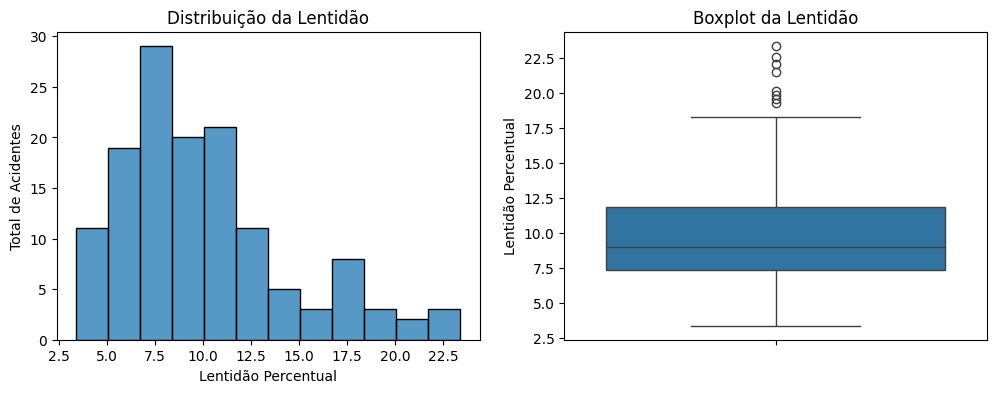

In [32]:
fig, axs = plt.subplots(1,2, figsize=(12,4))

sns.histplot(
    data=data,
    x='Slowness in traffic (%)',
    ax=axs[0]
)

sns.boxplot(
    data=data,
    y='Slowness in traffic (%)',
    ax=axs[1]
)

axs[0].set_title("Distribuição da Lentidão")
axs[0].set_xlabel("Lentidão Percentual")
axs[0].set_ylabel("Total de Acidentes")
axs[1].set_title("Boxplot da Lentidão")
axs[1].set_ylabel("Lentidão Percentual")
plt.show()

In [33]:
data[data['Slowness in traffic (%)']>18]

,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%),day_coded,has_incident,incident_total
76,23,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,19.6,2,1,2
77,24,0,1,0,0,0,0,0,0,2,0,3,0,0,0,1,0,20.2,2,1,7
78,25,1,3,0,2,0,0,0,0,4,0,1,0,0,0,4,0,22.6,2,1,15
79,26,1,0,0,0,0,0,0,0,3,0,0,0,0,0,0,0,23.4,2,1,4
80,27,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,19.3,2,0,0
104,24,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,18.3,3,0,0
105,25,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,19.9,3,1,1
106,26,0,0,0,0,0,0,0,0,0,0,3,1,0,0,0,0,21.5,3,1,4
107,27,0,3,0,1,0,0,0,0,1,0,7,0,2,0,1,0,22.1,3,1,15
131,24,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,18.1,4,1,2


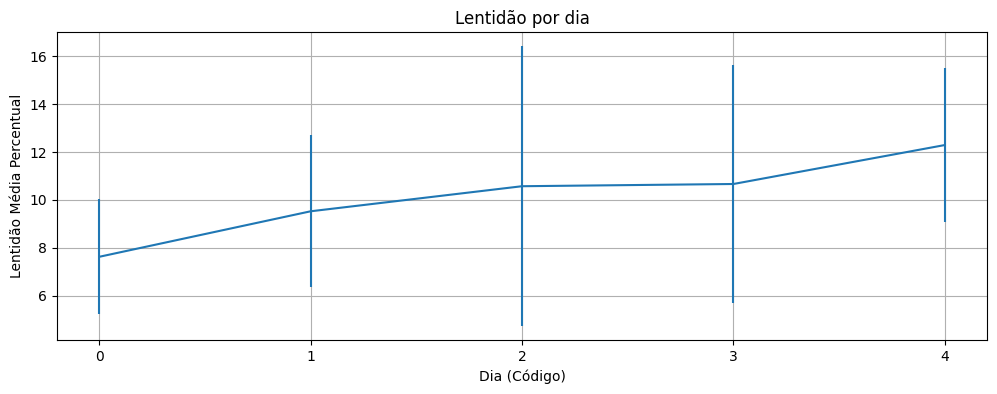

In [6]:
slow = "Slowness in traffic (%)"
plt.figure(figsize=(12,4))
slow_por_dia = data.groupby('day_coded')[slow].agg(["count", "mean", "std"])
plt.errorbar(
    x=slow_por_dia.index,
    y=slow_por_dia['mean'],
    yerr=slow_por_dia['std']
)
plt.xticks(slow_por_dia.index)
plt.title("Lentidão por dia")
plt.xlabel("Dia (Código)")
plt.ylabel("Lentidão Média Percentual")
plt.grid(True)
plt.show()

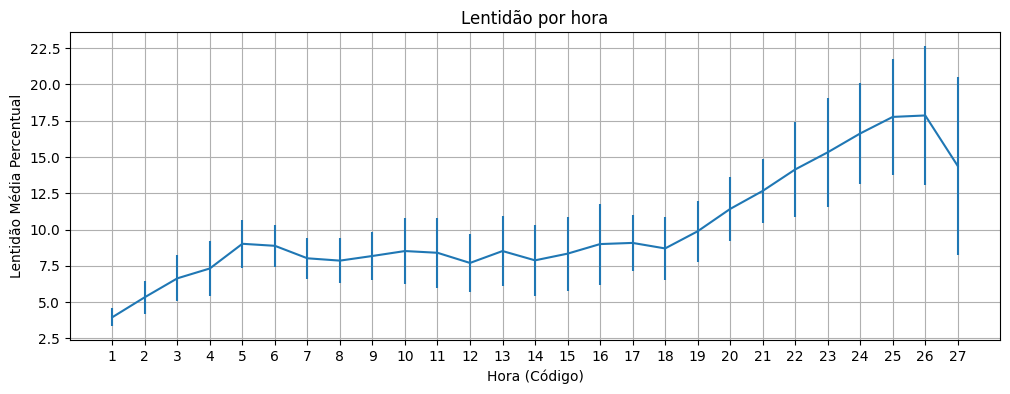

In [7]:
hour = "Hour (Coded)"
plt.figure(figsize=(12,4))
slow_por_hora = data.groupby(hour)[slow].agg(["count", "mean", "std"])
plt.errorbar(
    x=slow_por_hora.index,
    y=slow_por_hora['mean'],
    yerr=slow_por_hora['std']
)
plt.xticks(slow_por_hora.index)
plt.title("Lentidão por hora")
plt.xlabel("Hora (Código)")
plt.ylabel("Lentidão Média Percentual")
plt.grid(True)
plt.show()

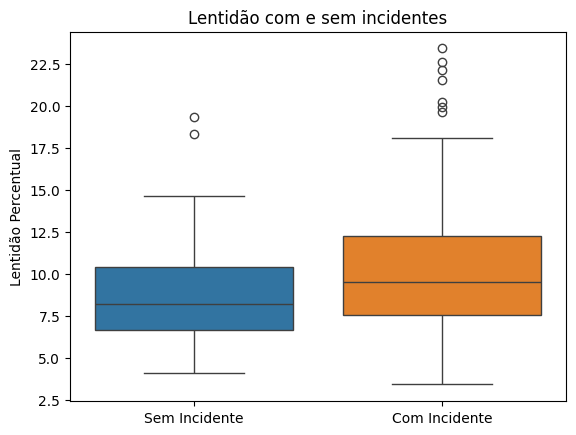

In [10]:
sns.boxplot(
    data=data,
    x="has_incident",
    y=slow,
    hue="has_incident",
    legend=False
)
plt.xticks([0,1],["Sem Incidente", "Com Incidente"])
plt.title("Lentidão com e sem incidentes")
plt.ylabel("Lentidão Percentual")
plt.xlabel("")
plt.show()

In [34]:
data[(data['Slowness in traffic (%)']>18) & (data['has_incident'] == 1)]

,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%),day_coded,has_incident,incident_total
76,23,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,19.6,2,1,2
77,24,0,1,0,0,0,0,0,0,2,0,3,0,0,0,1,0,20.2,2,1,7
78,25,1,3,0,2,0,0,0,0,4,0,1,0,0,0,4,0,22.6,2,1,15
79,26,1,0,0,0,0,0,0,0,3,0,0,0,0,0,0,0,23.4,2,1,4
105,25,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,19.9,3,1,1
106,26,0,0,0,0,0,0,0,0,0,0,3,1,0,0,0,0,21.5,3,1,4
107,27,0,3,0,1,0,0,0,0,1,0,7,0,2,0,1,0,22.1,3,1,15
131,24,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,18.1,4,1,2


In [35]:
data[(data['Slowness in traffic (%)']>15) & (data['has_incident'] == 0)]

,Hour (Coded),Immobilized bus,Broken Truck,Vehicle excess,Accident victim,Running over,Fire vehicles,Occurrence involving freight,Incident involving dangerous freight,Lack of electricity,Fire,Point of flooding,Manifestations,Defect in the network of trolleybuses,Tree on the road,Semaphore off,Intermittent Semaphore,Slowness in traffic (%),day_coded,has_incident,incident_total
80,27,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,19.3,2,0,0
104,24,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,18.3,3,0,0


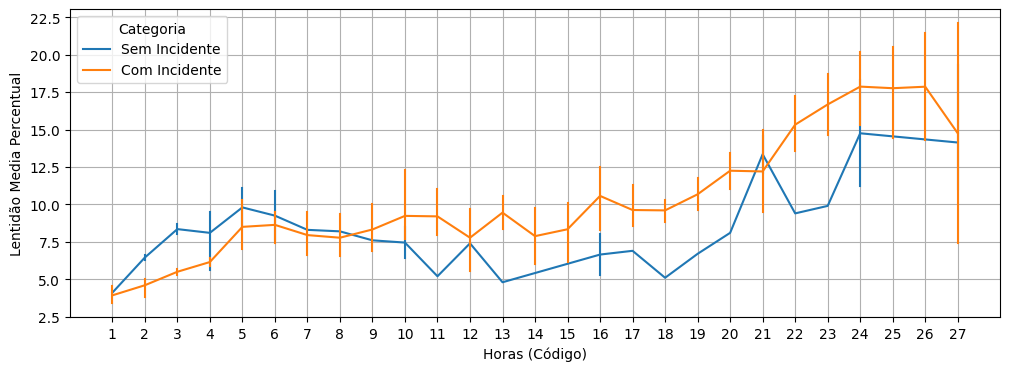

In [18]:
slipted_data = data.copy()
slipted_data["incident_id"] = data["has_incident"].map({0: "Sem Incidente", 1: "Com Incidente"})
plt.figure(figsize=(12,4))
sns.lineplot(
    data=slipted_data,
    x=hour,
    y=slow,
    hue="incident_id",
    estimator="mean",
    err_style='bars'
)
plt.xticks(range(1,28))
plt.xlabel("Horas (Código)")
plt.ylabel("Lentidão Media Percentual")
plt.legend(
    title="Categoria",
    loc="upper left"
)
plt.grid(True)
plt.show()

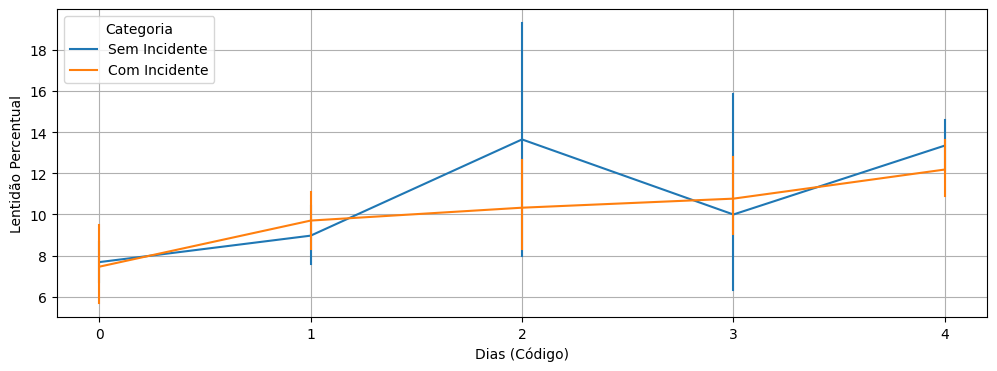

In [20]:
plt.figure(figsize=(12,4))
sns.lineplot(
    data=slipted_data,
    x="day_coded",
    y=slow,
    hue="incident_id",
    err_style='bars'
)
plt.xticks(range(0,5))
plt.ylabel("Lentidão Percentual")
plt.xlabel("Dias (Código)")
plt.legend(
    title="Categoria",
    loc="upper left"
)
plt.grid(True)
plt.show()

In [37]:
# Estátistica Inferencial
from scipy.stats import mannwhitneyu
statistic, p_value = mannwhitneyu(
    x=data.loc[data["has_incident"] == 0, slow],
    y=data.loc[data["has_incident"] == 1, slow],
    alternative="two-sided"
)

print(f"Estatística U:{statistic}")
print(f"P-value:{p_value}")

Estatística U:1392.0
P-value:0.07261791294539754


In [38]:
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests
resultados = []
for incidente in incidentes:
  rho, p_value = spearmanr(
    a=data[incidente],
    b=data[slow]
  )
  resultados.append({
      "incidente": incidente,
      "Rho": rho,
      "P-Valor" : p_value
  })

resultados_ajustados = pd.DataFrame(resultados)
resultados_ajustados["P-Ajustado"] = multipletests(
    pvals=resultados_ajustados["P-Valor"],
    method="fdr_bh"
)[1]
resultados_ajustados.sort_values(by="P-Ajustado")

,incidente,Rho,P-Valor,P-Ajustado
10,Point of flooding,0.337016,0.000064,0.001027
8,Lack of electricity,0.262365,0.002111,0.016891
14,Semaphore off,0.227628,0.007927,0.042279
0,Immobilized bus,0.160010,0.063765,0.204047
3,Accident victim,0.160818,0.062420,0.204047
15,Intermittent Semaphore,-0.152635,0.077171,0.205789
1,Broken Truck,0.125882,0.145722,0.315556
12,Defect in the network of trolleybuses,-0.122256,0.157778,0.315556
5,Fire vehicles,0.115286,0.183029,0.325385
13,Tree on the road,-0.097321,0.261471,0.418354


In [39]:
import statsmodels.formula.api as smf
resultados = []
for incidente in incidentes:
  modelo = smf.ols(
      formula=f'Q("{slow}") ~ Q("{incidente}") + C(day_coded) + C(Q("Hour (Coded)"))',
      data=data
  ).fit(cov_type="HC3")
  resultados.append({
      "Incidente": incidente,
      "P-Valor": modelo.pvalues[f'Q("{incidente}")']
  })

resultados_ajustados = pd.DataFrame(resultados)
resultados_ajustados["P-Ajustado"] = multipletests(
    pvals=resultados_ajustados["P-Valor"],
    method="fdr_bh"
)[1]
resultados_ajustados.sort_values(by="P-Ajustado")


,Incidente,P-Valor,P-Ajustado
8,Lack of electricity,0.000490,0.007842
10,Point of flooding,0.001739,0.013911
14,Semaphore off,0.003678,0.019614
15,Intermittent Semaphore,0.082561,0.330245
13,Tree on the road,0.195564,0.625804
4,Running over,0.261868,0.698314
3,Accident victim,0.414091,0.946493
1,Broken Truck,0.946881,0.997624
7,Incident involving dangerous freight,0.949787,0.997624
6,Occurrence involving freight,0.563058,0.997624
